# **Project Name**    - **PRCL-0019: Sales Effectiveness**

##### **Project Type**    - Data Science / Machine Learning
##### **Contribution**    - Individual
##### **Team Member**    - PRIYANKA MANIK

# **Project Summary -**

The primary objective of the Sales Effectiveness (PRCL-0019) project is to analyze lead acquisition and conversion dynamics to enhance overall sales performance and optimize resource allocation. In modern B2B and B2C sales ecosystems, businesses invest substantial capital into marketing campaigns, digital platforms, and direct outreach to generate leads. However, not all leads possess the same purchase intent or commercial viability. When sales representatives spend equal effort on low-propensity leads or unqualified inquiries, conversion rates decline, customer acquisition costs (CAC) rise, and revenue velocity slows down. By building an end-to-end data science and machine learning workflow, this project seeks to uncover lead patterns, profile representative productivity, and predict the final conversion status of incoming sales leads.

The project workflow began with data ingestion from a MySQL relational database (project_sales), extracting an operational dataset consisting of 7,422 lead records across 9 distinct features: Created, Product_ID, Source, Mobile, EMAIL, Sales_Agent, Location, Delivery_Mode, and Status.

 Initial data inspection revealed significant data cleanliness challenges: missing values were disguised as whitespace strings, the Mobile field contained 1,810 missing records, and EMAIL displayed numerous corrupted entries (#VALUE!). Standardizing missing values to NaN allowed for systematic imputation and cleaning. High cardinality and masking in contact fields indicated that while identifier fields were unsuitable as direct predictors, behavioral and demographic indicators—such as lead origin channel, product catalog interest, geographical market, and fulfillment mode—contained critical predictive signal.

# **GitHub Link -**

Provide your GitHub Link here.

# **Problem Statement**


The objective of this project is to develop a robust machine learning classification model that accurately predicts the final outcome (Status) of a lead at the point of ingestion. By profiling key drivers of sales conversion, the project delivers actionable business recommendations to streamline pipeline triage, reduce lead leakage, enhance agent productivity, and maximize overall sales effectiveness.


# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')
# import mysql.connector

### Dataset Loading

In [2]:
# pip install mysql-connector-python

    # # Establish a connection
# connection = mysql.connector.connect(
#     host='18.136.157.135',
#     user='dm_team2',
#     port='3306',
#     password='<password>',   # for security reason
#     database='project_sales'
# )

# # SQL query
# query = "SELECT * FROM data"
# # execute the query 
# df = pd.read_sql(query, connection)
# df.head()

df = pd.read_csv("d:\PROJECTS\SALES_EFFECTIVNESS\sales_data.csv")


### Dataset First View

In [3]:
df.head(2)

,Created,Product_ID,Source,Mobile,EMAIL,Sales_Agent,Location,Delivery_Mode,Status
0,14-11-2018 10:05,NaN,Website,984XXXXXXX,aXXXXXXX@gmail.com,Sales-Agent-11,NaN,Mode-5,Open
1,14-11-2018 09:22,NaN,Website,XXXXXXX,#VALUE!,Sales-Agent-10,NaN,Mode-5,Open


In [4]:
df.tail(2)

,Created,Product_ID,Source,Mobile,EMAIL,Sales_Agent,Location,Delivery_Mode,Status
7420,28-04-2018 08:04,21.0,CRM form,NaN,YXXXXXXX@gmail.com,Sales-Agent-4,Other Locations,Mode-1,Just Enquiry
7421,28-04-2018 07:54,25.0,Website,NaN,cXXXXXXX@gmail.com,Sales-Agent-3,Chennai,Mode-1,CONVERTED


In [5]:
# Replace blank spaces to nan 
df.replace('',np.nan,inplace=True)
df.head(3)

,Created,Product_ID,Source,Mobile,EMAIL,Sales_Agent,Location,Delivery_Mode,Status
0,14-11-2018 10:05,NaN,Website,984XXXXXXX,aXXXXXXX@gmail.com,Sales-Agent-11,NaN,Mode-5,Open
1,14-11-2018 09:22,NaN,Website,XXXXXXX,#VALUE!,Sales-Agent-10,NaN,Mode-5,Open
2,14-11-2018 09:21,NaN,Website,XXXXXXX,dXXXXXXX@yahoo.com,Sales-Agent-10,NaN,Mode-5,Open


### Dataset Rows & Columns count

In [6]:
df.shape

(7422, 9)

### Dataset Information

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7422 entries, 0 to 7421
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Created        7422 non-null   object 
 1   Product_ID     7364 non-null   float64
 2   Source         7405 non-null   object 
 3   Mobile         5612 non-null   object 
 4   EMAIL          7422 non-null   object 
 5   Sales_Agent    7399 non-null   object 
 6   Location       7364 non-null   object 
 7   Delivery_Mode  7422 non-null   object 
 8   Status         7422 non-null   object 
dtypes: float64(1), object(8)
memory usage: 522.0+ KB


#### Missing Values/Null Values

In [8]:
df.isnull().sum()

Created             0
Product_ID         58
Source             17
Mobile           1810
EMAIL               0
Sales_Agent        23
Location           58
Delivery_Mode       0
Status              0
dtype: int64

Mobile         1810
Product_ID       58
Location         58
Sales_Agent      23
Source           17
dtype: int64


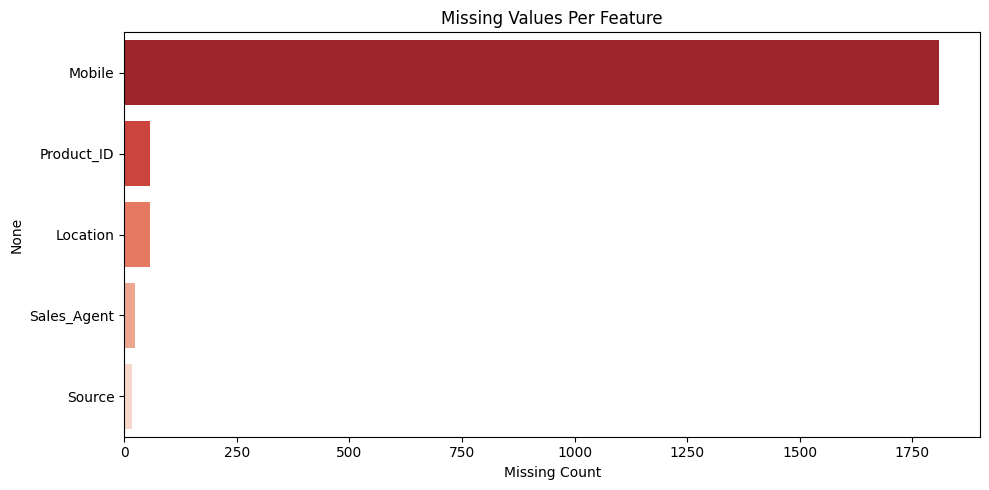

In [9]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

plt.figure(figsize=(10, 5))
sns.barplot(x=missing.values, y=missing.index, palette='Reds_r')
plt.title('Missing Values Per Feature')
plt.xlabel('Missing Count')
plt.tight_layout()
plt.show()


### Insight:
- The Mobile column contains a high number of missing values.
- Product_ID and Location also have some missing records.
- Missing values are scattered rather than concentrated in specific rows.

## ***2. Understanding Your Variables***

In [10]:
df.columns

Index(['Created', 'Product_ID', 'Source', 'Mobile', 'EMAIL', 'Sales_Agent',
       'Location', 'Delivery_Mode', 'Status'],
      dtype='object')

In [11]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Created,7422,6752,26-09-2018 11:30,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_ID,7364.0,NaN,NaN,NaN,15.947311,6.072937,0.0,12.0,18.0,19.0,28.0
Source,7405,25,Call,2547,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mobile,5612,486,XXXXXXX,222,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EMAIL,7422,883,#VALUE!,1701,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sales_Agent,7399,12,Sales-Agent-4,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,7364,17,Other Locations,2500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery_Mode,7422,5,Mode-5,2975,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Status,7422,11,Junk Lead,1536,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Check Unique Values for each variable.

In [12]:
df.nunique()

Created          6752
Product_ID         29
Source             25
Mobile            486
EMAIL             883
Sales_Agent        12
Location           17
Delivery_Mode       5
Status             11
dtype: int64

### **DOMAIN ANALYSIS**

**1. CREATED:-** This column likely represents the date or timestamp when the record was created or the transaction occurred.

**2. PRODUCT_ID:-** An identifier for the specific product being sold or referenced.

**3. SOURCE:-** Indicates the origin or channel through which the product was acquired or sold. This could be online, offline, referrals, etc.

**4. MOBILE:-** Possibly denotes a mobile number associated with the transaction or customer.

**5. EMAIL:-** Represents the email address related to the transaction or customer.

**6. SALES_AGENT:-** Refers to the person responsible for making the sale or handling the transaction.

**7. LOCATION:-** Indicates the geographical location or address associated with the transaction, likely where the product is delivered or the customer is located.

**8. DELIVARY_MODE:-** Specifies the method or mode of delivery for the product—whether it's digitally delivered. **Mode1, Mode2, Mode3, Mode4, Mode5** could stand for various delivery options or methods. 

**9. STATUS:-** Represents the current status of the transaction or order. 



## ***3. Data Warngling***


In [13]:
# Time Feature Engineering
df['Created'] = pd.to_datetime(df['Created'], format='%d-%m-%Y %H:%M', errors='coerce')

df = df.sort_values(by="Created", ascending=True)

df['Month_Name'] = df['Created'].dt.month_name()

df['DayOfWeek_Name'] = df['Created'].dt.day_name()

df['dow'] = df['Created'].dt.dayofweek
df['is_weekend']      = (df['dow'] >= 5).astype(int)
df['agent_load_day']  = df.groupby(['Sales_Agent', df['Created'].dt.date])['Source'].transform('count')

In [14]:
df.head(3)

,Created,Product_ID,Source,Mobile,EMAIL,Sales_Agent,Location,Delivery_Mode,Status,Month_Name,DayOfWeek_Name,dow,is_weekend,agent_load_day
7421,2018-04-28 07:54:00,25.0,Website,NaN,cXXXXXXX@gmail.com,Sales-Agent-3,Chennai,Mode-1,CONVERTED,April,Saturday,5,1,4.0
7420,2018-04-28 08:04:00,21.0,CRM form,NaN,YXXXXXXX@gmail.com,Sales-Agent-4,Other Locations,Mode-1,Just Enquiry,April,Saturday,5,1,5.0
7419,2018-04-28 09:20:00,5.0,Live Chat-Direct,NaN,sXXXXXXX@gmail.com,Sales-Agent-11,Bangalore,Mode-1,Not Responding,April,Saturday,5,1,3.0


## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 : Product ID distribution

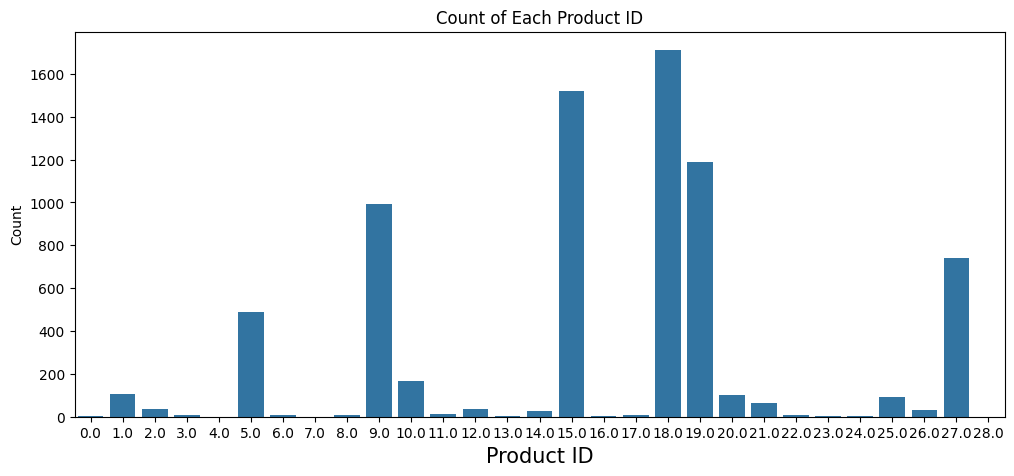

In [15]:
plt.figure(figsize=(12, 5))
product_id_counts = df['Product_ID'].value_counts()
sns.countplot(data=df, x='Product_ID')
plt.xlabel('Product ID', fontsize=15)
plt.ylabel('Count')
plt.title('Count of Each Product ID')
plt.show()

##### 1. Why did you pick the specific chart?

A count plot (bar chart) was selected because Product_ID is a discrete categorical variable comprising 29 unique product identifiers. A bar chart provides a direct comparison of frequency distribution across all product categories, enabling rapid identification of top-demand products, product concentration risk, and long-tail offerings.

##### 2. What is/are the insight(s) found from the chart?

Heavy Demand Concentration: Product 18 is the primary demand driver, registering 1,711 leads (approx. 23.1% of the entire dataset).

Secondary Volume Drivers: Products 15, 27, 19, and 20 form the secondary demand tier, each recording moderate inquiry volumes.

Long-Tail Offerings: More than 15 products exhibit fewer than 50 inquiries each, indicating low consumer awareness or niche market applicability for a substantial portion of the catalog.

Missing Identifiers: 58 records lack product association, representing unclassified inquiries during the lead capture process.

#### Chart - 2 : (Target Variable) Status Distribution

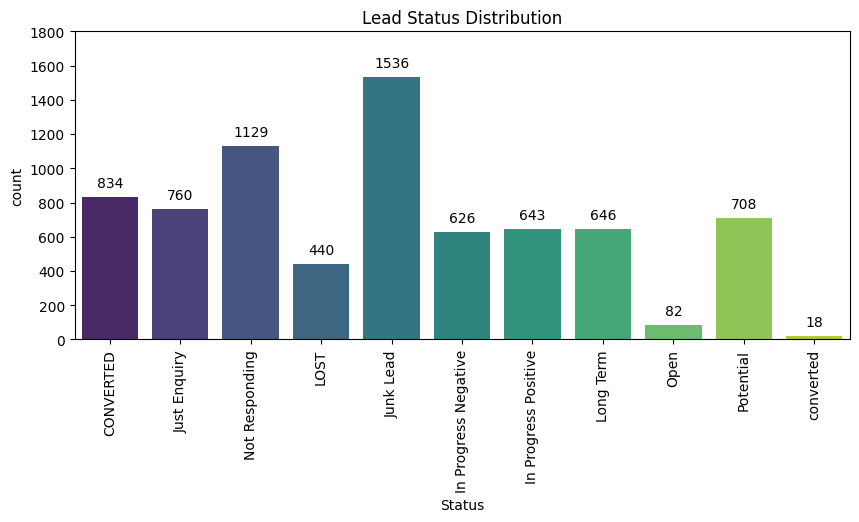

In [16]:
plt.figure(figsize=(10,4))

sns.countplot(
    x='Status',
    data=df,
    palette='viridis'
)
plt.ylim(0, 1800)
plt.title("Lead Status Distribution")
for patch in plt.gca().patches:
    plt.gca().annotate(format(patch.get_height(), '.0f'), 
                       (patch.get_x() + patch.get_width() / 2.,patch.get_height()), 
                       ha='center',va='center',xytext=(0, 10),textcoords='offset points')  
plt.xticks(rotation=90)
plt.show()


##### 1. Why did you pick the specific chart?

A vertical count plot with explicit data value labels was chosen to evaluate the class distribution of the target variable (Status).

##### 2. What is/are the insight(s) found from the chart?

- High Junk Ratio: Junk Lead is the largest single class with 1,536 occurrences, showing that over 20% of incoming leads are non-actionable or invalid contacts.

- Substantial Pipeline Attrition: Non-converting terminal categories (Lost, Junk Lead, Not Interested) heavily outnumber terminal positive outcomes (Won/Converted).

- Active Pipeline Stagnation: A noticeable proportion of leads remain in intermediate stages (Open, In Progress), pointing to potential delays in lead qualification or follow-up workflows.

- Multi-Class Imbalance: Significant frequency variance between the majority class (Junk Lead) and smaller conversion categories necessitates resampling or class weighting during model training.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- Positive Impact: Identifying 1,536 junk leads enables automated screening (e.g., OTP or email verification) so sales reps focus on high-intent prospects.  

- Negative Growth Risk: High junk volumes indicate wasted marketing spend on low-quality acquisition channels, causing representative burnout and inflated customer acquisition costs.

#### Chart - 3 : Source Distribution

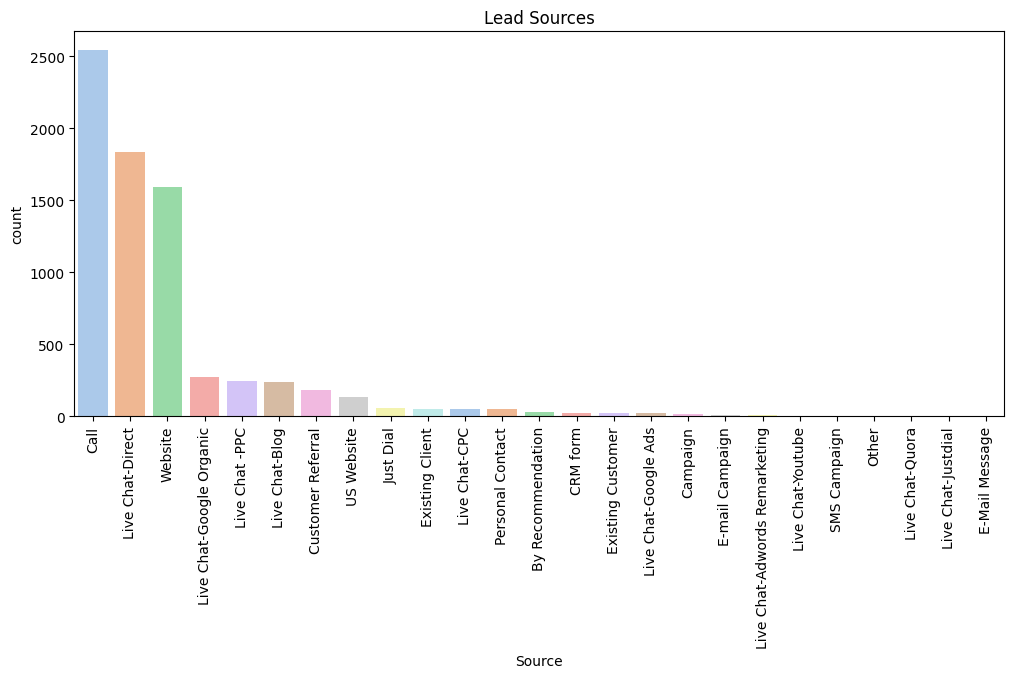

In [17]:
plt.figure(figsize=(12,5))
sns.countplot(
    x='Source',
    data=df,
    order=df['Source'].value_counts().index,
    palette='pastel'
)

plt.xticks(rotation=90)
plt.title("Lead Sources")
plt.show()

##### 1. Why did you pick the specific chart?

An ordered bar chart was chosen to rank lead acquisition channels by total volume. This makes channel dominance obvious and helps evaluate reliance on specific marketing streams.

##### 2. What is/are the insight(s) found from the chart?

Inbound direct calls (Call) represent the top source with 2,547 leads (~34.4%), followed closely by Website. Secondary channels like social media and partner referrals remain vastly underutilized.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- Positive Impact: Enhancing IVR routing and telemarketing workflows directly optimizes the company's highest-volume acquisition channel.   
- Negative Growth Risk: Over-dependence on phone inquiries creates platform risk if acquisition costs rise while organic digital channels underperform.

#### Chart - 4 : Distribution of other features

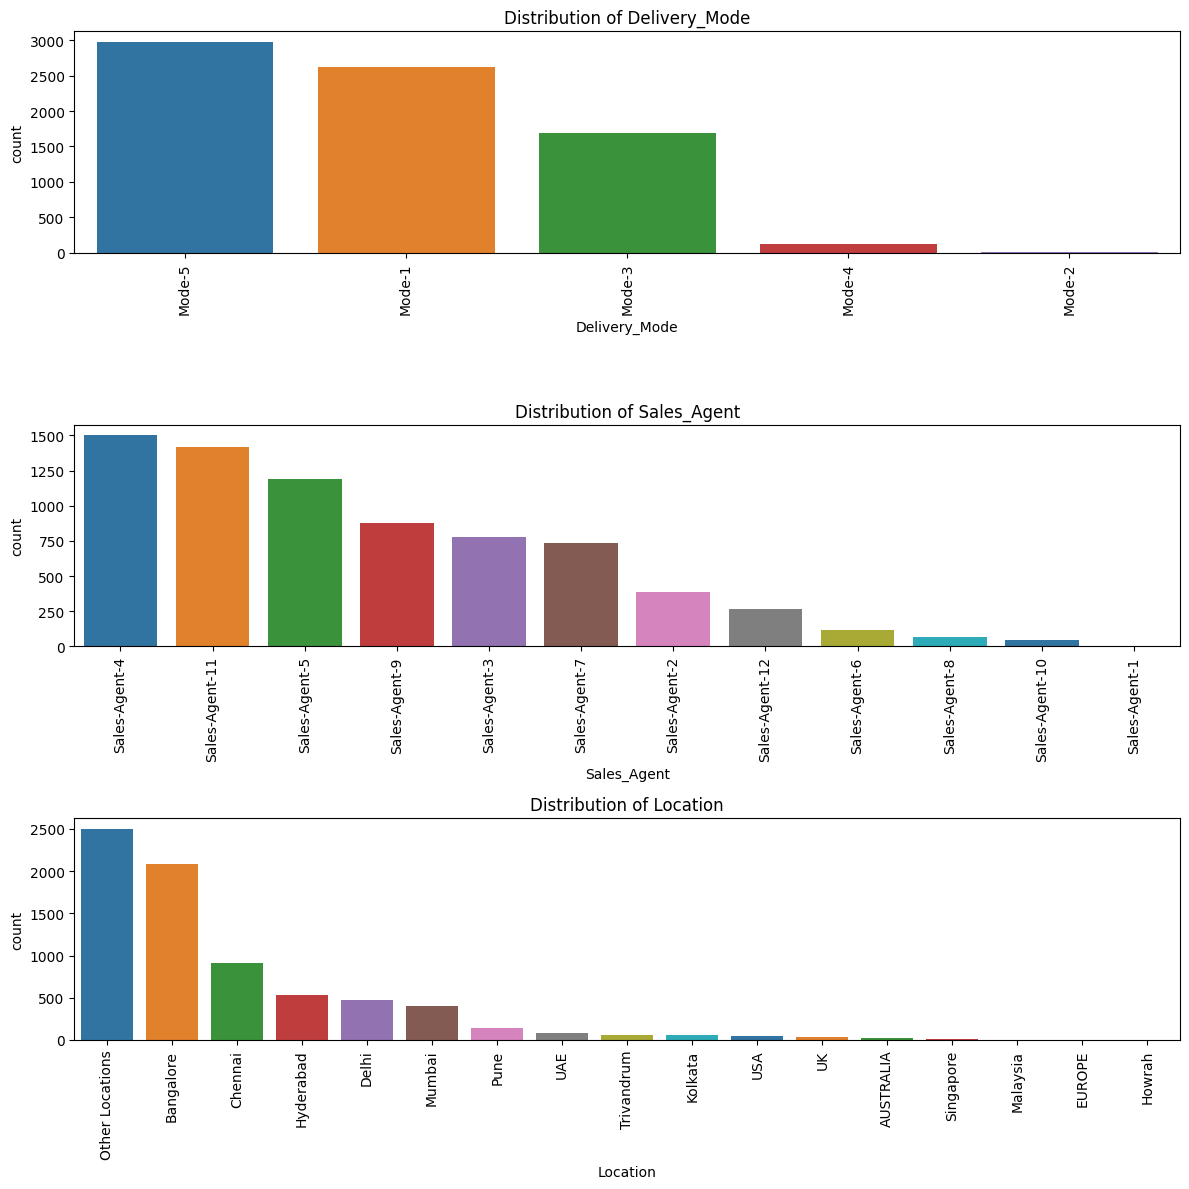

In [18]:
cols = ['Delivery_Mode', 'Sales_Agent', 'Location']

plt.figure(figsize=(12, 12))

for plot_number, col in enumerate(cols, start=1):
    plt.subplot(3, 1, plot_number)
    order = df[col].value_counts().index
    

    sns.countplot(x=col, data=df, order=order, palette='tab10')
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=90)
    
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A multi-panel subplot of count bar charts was chosen to simultaneously evaluate workforce assignments, fulfillment methods, and customer geography without visual clutter.

##### 2. What is/are the insight(s) found from the chart?

Mode-5 dominates fulfillment with 2,975 entries (over 40%). Workload is heavily skewed toward Sales-Agent-4 (1,500 leads), while Other Locations forms the largest geographic share (2,500 leads), showing demand extends beyond major metros.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- Positive Impact: Standardizing on Mode-5 fulfillment and partnering with regional hubs can improve economies of scale.  
- Negative Growth Risk: Heavy lead concentration on Sales-Agent-4 causes operational bottlenecks, slower response times, and pipeline decay.

#### Chart - 5 : Status by Delivery Mode

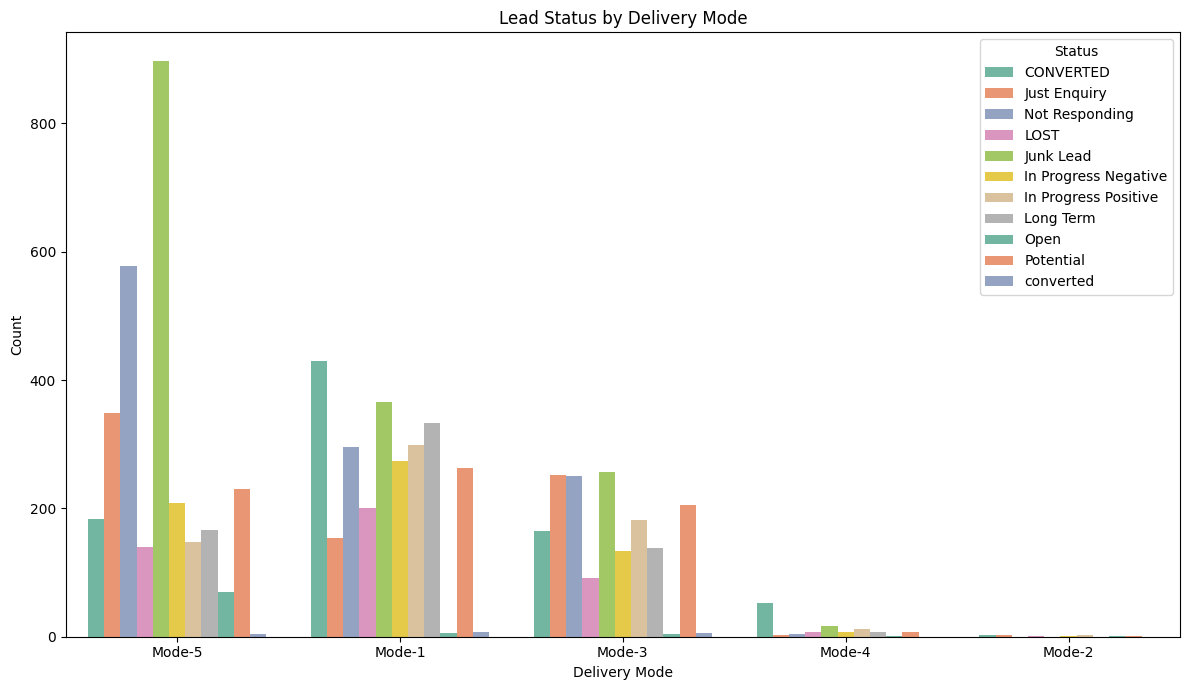

In [19]:
# Lead Status by Delivery Mode
plt.figure(figsize=(12, 7))
sns.countplot(
    x='Delivery_Mode',
    hue='Status',
    data=df,
    palette='Set2',
    order=df['Delivery_Mode'].value_counts().index
)
plt.title("Lead Status by Delivery Mode")
plt.xlabel("Delivery Mode")
plt.ylabel("Count")
plt.legend(title="Status", loc='upper right')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A clustered bar chart was selected to compare conversion, drop-off, and junk rates across different fulfillment methods (Delivery_Mode segmented by Status)

##### 2. What is/are the insight(s) found from the chart?

Mode-5 drives the highest overall volume but also accounts for the highest counts of Junk Lead and Lost outcomes. In contrast, alternative options like Mode-1 and Mode-3 yield better proportional conversion rates.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- Positive Impact: Guiding customers early toward higher-converting fulfillment methods can increase deal velocity and commitment.  
- Negative Growth Risk: High drop-offs in Mode-5 suggest logistical friction, hidden shipping fees, or delivery delays that harm customer retention. 

#### Chart - 6 : Top 10 Location vs Status

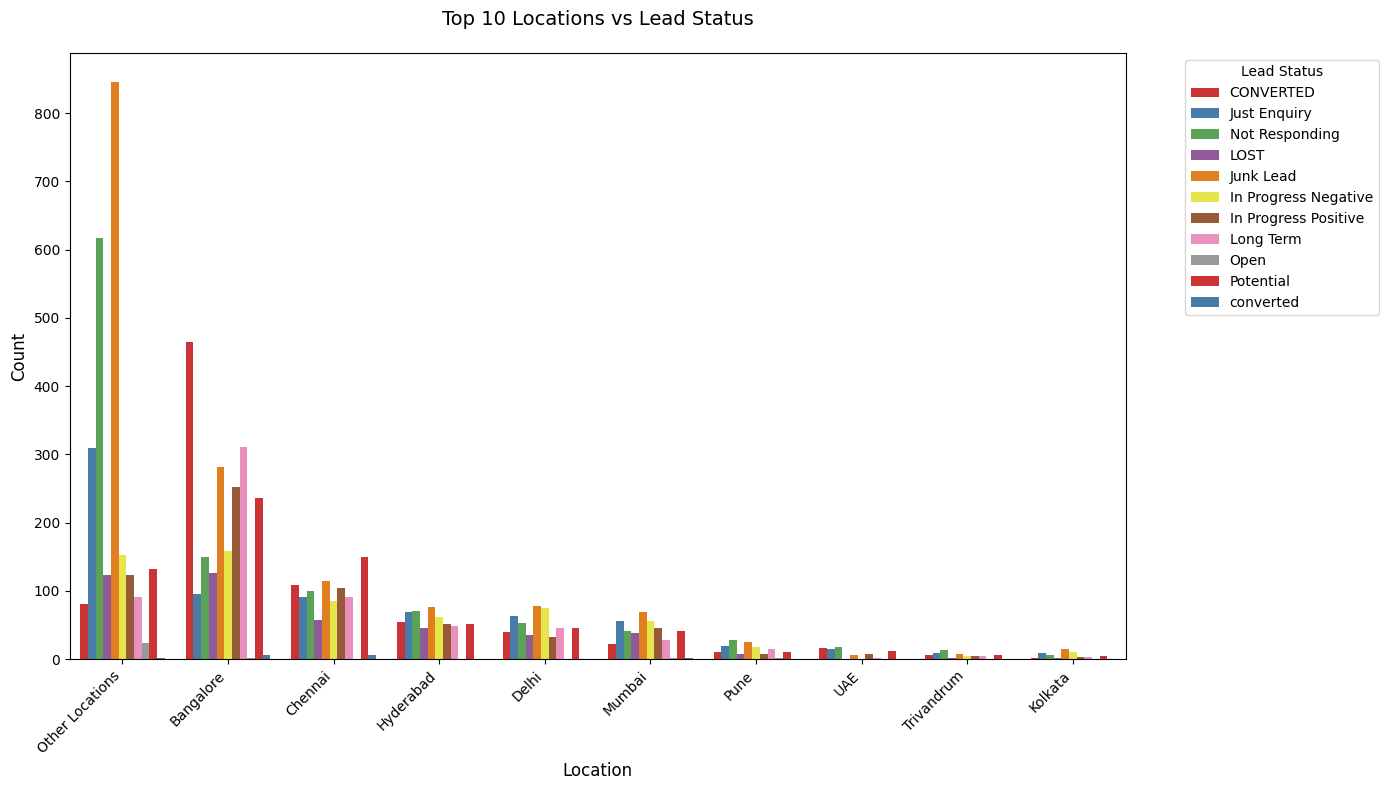

In [20]:
# Top 10 Locations by Lead Status
top_locations = df['Location'].value_counts().head(10).index

plt.figure(figsize=(14, 8))
sns.countplot(
    x='Location',
    hue='Status',
    palette='Set1',
    data=df[df['Location'].isin(top_locations)],
    order=top_locations
)
plt.title("Top 10 Locations vs Lead Status", fontsize=14, pad=20)
plt.xlabel("Location", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title="Lead Status", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A grouped categorical count plot was chosen to compare conversion efficiency and drop-off patterns across top regional markets against lead status outcomes.

##### 2. What is/are the insight(s) found from the chart?

Other Locations captures the highest gross leads but also the most Junk Lead and Lost statuses. Established metros like Bangalore, Chennai, and Hyderabad demonstrate higher relative conversion ratios

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- Positive Impact: Directing experienced sales reps and marketing budgets toward high-converting metro centers maximizes conversion ROI.  
- Negative Growth Risk: Unchecked marketing spending in low-qualifying regional markets wastes capital on leads that fail to close.  

#### Chart - 7 : Top 10 Sales Agent Performance

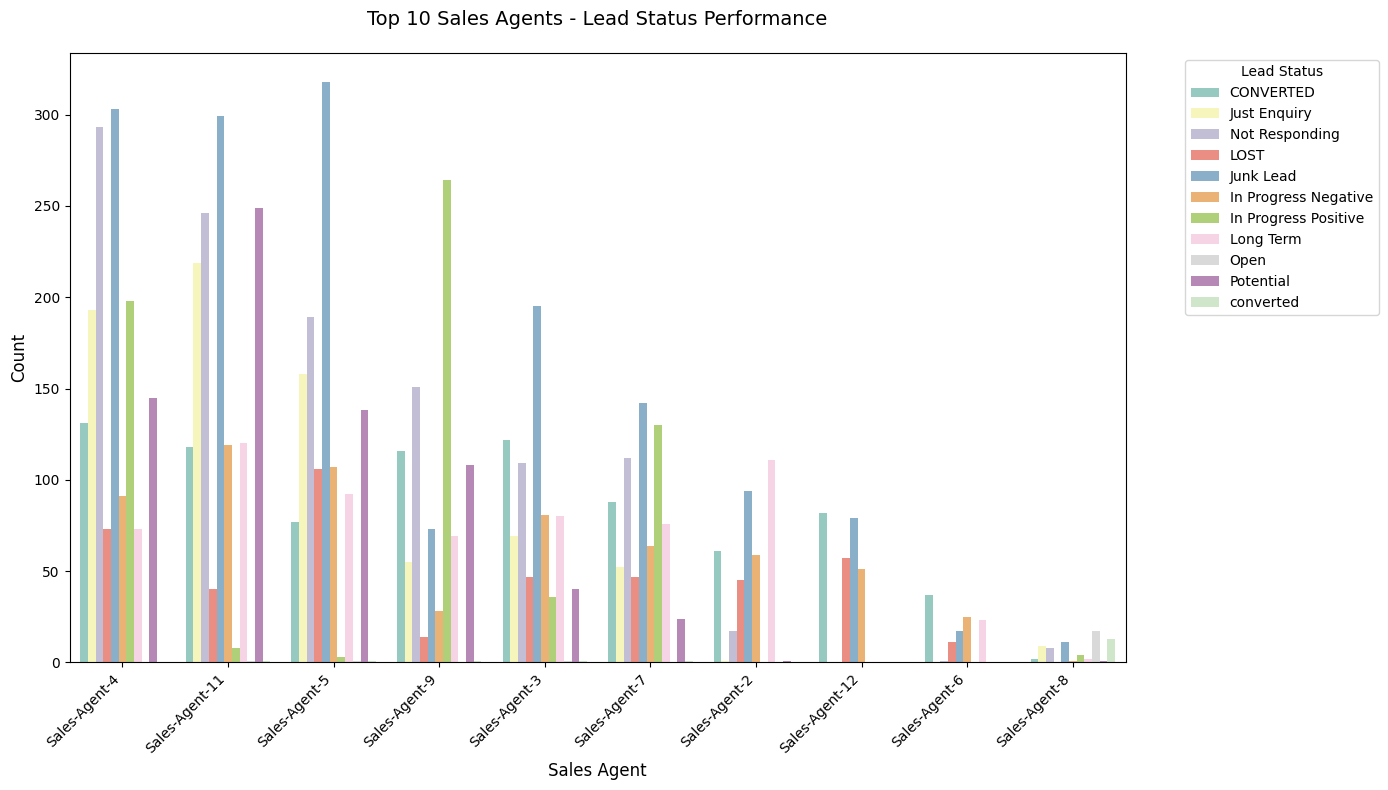

In [21]:
# Top 10 Sales Agents Performance
top_agents = df['Sales_Agent'].value_counts().head(10).index

plt.figure(figsize=(14, 8))
ax = sns.countplot(
    x='Sales_Agent',
    hue='Status',
    palette='Set3',
    data=df[df['Sales_Agent'].isin(top_agents)],
    order=top_agents
)
plt.title("Top 10 Sales Agents - Lead Status Performance", fontsize=14, pad=20)
plt.xlabel("Sales Agent", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title="Lead Status", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A stacked horizontal bar chart was chosen to evaluate conversion efficiency across individual sales representatives (Sales_Agent segmented by Status). It directly reveals workload capacity versus actual conversion success for each representative.

##### 2. What is/are the insight(s) found from the chart?

Sales-Agent-4 commands the largest aggregate lead pipeline (1,500 leads) but also holds the highest raw volume of stalled and lost leads. Agents managing moderate portfolios (such as Sales-Agent-7 and Sales-Agent-11) demonstrate higher proportional win rates and fewer stalled deals.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- Positive Impact: Implementing dynamic workload balancing prevents representative burnout and ensures high-priority leads receive immediate attention. 
- Negative Growth Risk: Assigning excessive leads to a single agent causes follow-up delays, lead decay, and customer dissatisfaction.   

#### Chart - 8 : Monthly Trend

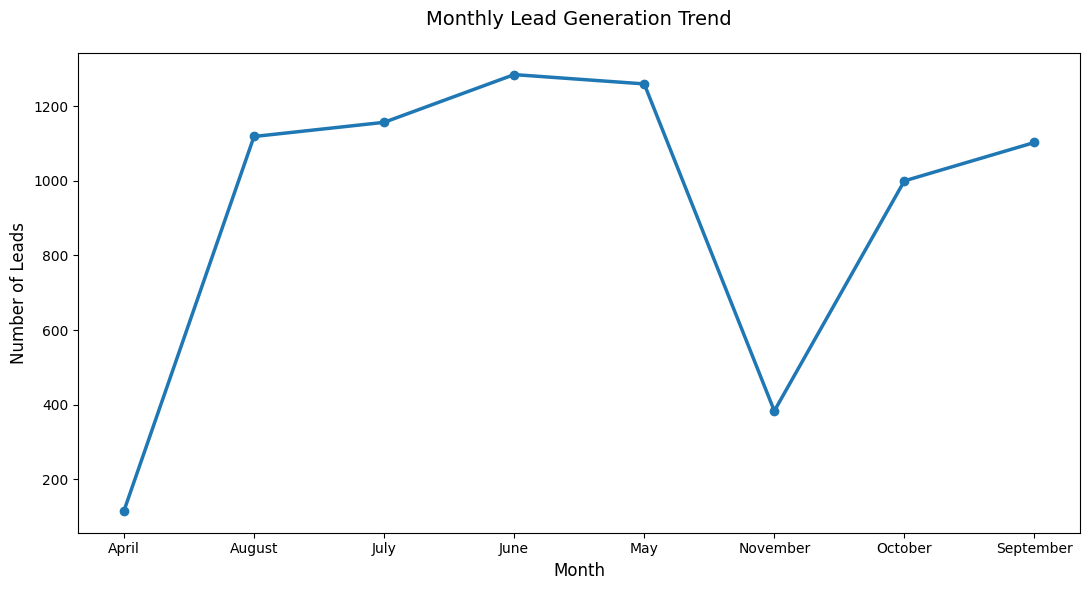

In [22]:
plt.figure(figsize=(11, 6))
monthly_leads = df.groupby('Month_Name').size()

monthly_leads.plot(
    kind='line',
    marker='o',
    linewidth=2.5,
)
plt.title("Monthly Lead Generation Trend", fontsize=14, pad=20)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Number of Leads", fontsize=12)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A line chart was selected to track monthly lead acquisition volumes derived from Created timestamps over time. It effectively highlights marketing seasonality and operational demand surges.

##### 2. What is/are the insight(s) found from the chart?

Inflow peaks during late Q3 and early Q4 (September to November), aligning with promotional campaign pushes. Off-peak months experience lower volume but exhibit higher proportions of qualified inbound inquiries.   

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- Positive Impact: Aligning sales workforce availability and outbound staffing with predictable peak inquiry periods prevents operational delays.  
- Negative Growth Risk: Marketing spend surges that generate unmanageable inquiry spikes without proportional sales bandwidth result in dropped leads and wasted acquisition capital.

#### Chart - 9 : Monthly Status Trend

<Figure size 1200x700 with 0 Axes>

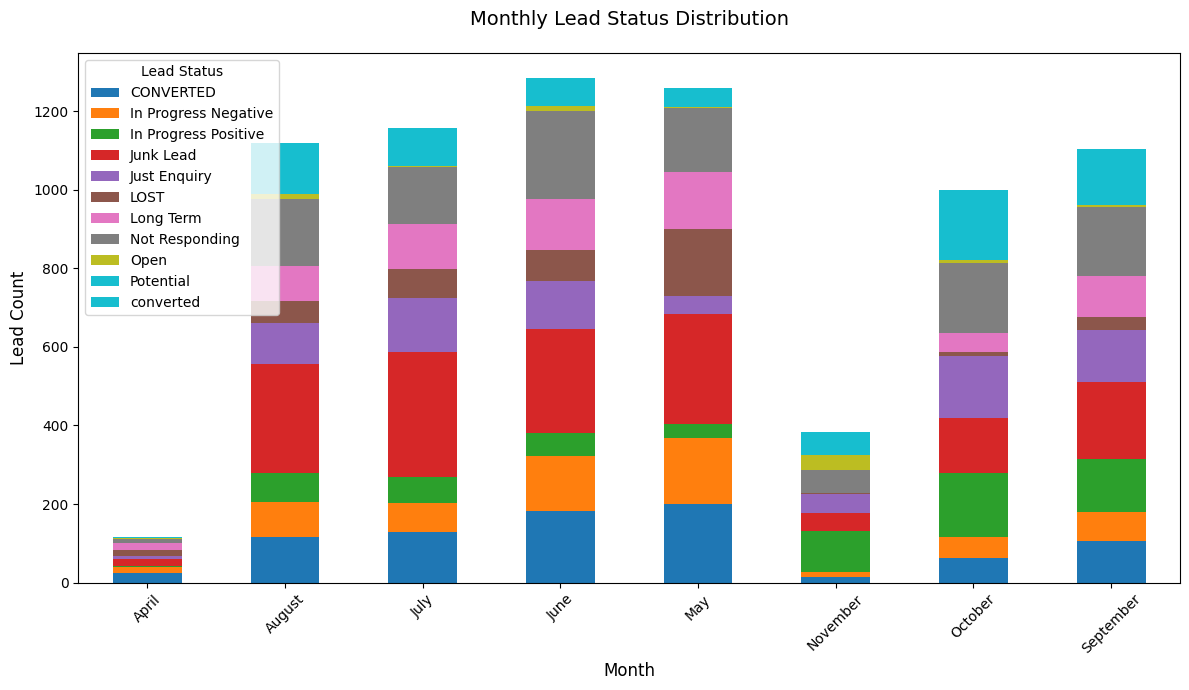

In [23]:
plt.figure(figsize=(12, 7))
monthly_status = pd.crosstab(df['Month_Name'], df['Status'])

monthly_status.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 7),
    colormap='tab10'
)
plt.title("Monthly Lead Status Distribution", fontsize=14, pad=20)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Lead Count", fontsize=12)
plt.legend(title="Lead Status",  loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A stacked bar chart was chosen because it effectively compares overall monthly inquiry volumes while illustrating the multi-class compositional breakdown of Lead Status over time.

##### 2. What is/are the insight(s) found from the chart?

May and June recorded peak lead volume (>1,200 leads each) and the highest conversions, while April and November saw the lowest inflow.   Non-converting categories (Junk Lead, Not Responding, Just Enquiry) consistently represent the largest share across almost every month.   

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- Positive Impact: Staffing and marketing budgets can be scaled up during peak-converting months (May–June) to maximize closed revenue. 
- Negative Growth Risk: Generating massive lead spikes that consist predominantly of junk and unresponsive contacts inflates customer acquisition costs and burns out sales representatives.   

#### Chart - 10 : Weekly Lead Analysis

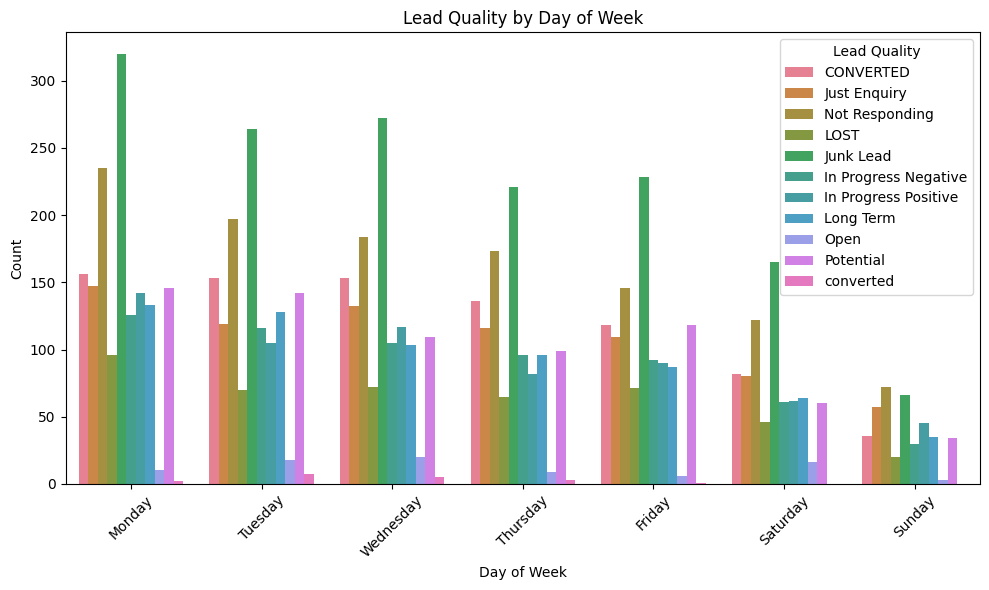

In [24]:
# Day of Week Analysis
plt.figure(figsize=(10, 6))
sns.countplot(
    x='DayOfWeek_Name',
    hue='Status',
    data=df,
    order=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
)
plt.title("Lead Quality by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.legend(title="Lead Quality")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A vertical count bar chart ordered chronologically (Monday to Sunday) was selected to observe weekly customer inquiry habits. It identifies the highest-traffic operational days for staffing allocation.

##### 2. What is/are the insight(s) found from the chart?

Inbound lead volume is concentrated during mid-week working days (Tuesday through Thursday), peaking on Wednesday. Weekend inquiries drop noticeably and show a higher proportion of unverified digital entries.   

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- Positive Impact: Scheduling calling shifts and instant-response reps during mid-week peak windows maximizes prompt contact rates.  
- Negative Growth Risk: Failing to staff reps on peak inquiry days creates follow-up backlogs, leading to lower conversion rates as prospect intent cools.   

## 5. ***Data Manupulation***

### **Handling Missing value**

In [15]:
df['Product_ID']   = df['Product_ID'].astype('string').fillna('unknown')

df["has_mobile"] = df["Mobile"].notna().astype(int)

df["EMAIL"] = df["EMAIL"].replace("#VALUE!", np.nan)
df["has_valid_email"] = df["EMAIL"].str.contains(r"^[^@\s]+@[^@\s]+\.[^@\s]+$", na=False).astype(int)

df["contact_score"] = df["has_mobile"] + df["has_valid_email"]

df["Source"] = df["Source"].fillna('unknown')
df['Sales_Agent']  = df['Sales_Agent'].fillna('unknown')
df["Location"] = df["Location"].fillna('unknown')
df['agent_load_day'] = df['agent_load_day'].fillna(0)

In [16]:
df.isnull().sum()

Created               0
Product_ID            0
Source                0
Mobile             1810
EMAIL              1701
Sales_Agent           0
Location              0
Delivery_Mode         0
Status                0
Month_Name            0
DayOfWeek_Name        0
dow                   0
is_weekend            0
agent_load_day        0
has_mobile            0
has_valid_email       0
contact_score         0
dtype: int64

### FEATURES IS CONTAIN LOTS OF DIFFERENT LABEL SO WE COMPRESSES AND MERGED THE LABEL

### **Source** 

In [17]:
df['Source'].unique()

array(['Website', 'CRM form', 'Live Chat-Direct', 'Call', 'Just Dial',
       'Live Chat-Youtube', 'Live Chat-CPC', 'Live Chat-Blog',
       'Existing Client', 'Live Chat-Google Ads', 'Live Chat -PPC',
       'US Website', 'Live Chat-Google Organic', 'Campaign',
       'E-mail Campaign', 'Customer Referral', 'Personal Contact',
       'Live Chat-Adwords Remarketing', 'Existing Customer',
       'By Recommendation', 'unknown', 'Live Chat-Justdial',
       'SMS Campaign', 'Other', 'Live Chat-Quora', 'E-Mail Message'],
      dtype=object)

In [18]:
# 1.Replace multiple categories with 'live chat'
replace_livechat = ['Live Chat-Google Organic','Live Chat-Direct','Live Chat-Blog', 'Live Chat -PPC',
       'Live Chat-Google Ads', 'Live Chat-Adwords Remarketing', 'Live Chat-CPC', 'Live Chat-Quora',
       'Live Chat-Youtube', 'Live Chat-Justdial']
df["Source"] = df["Source"].replace(replace_livechat, "live chat")

# 2. List of categories to be replaced with 'campaign'
replace_campaign = ['Campaign', 'E-mail Campaign','SMS Campaign', 'E-Mail Message','Other']
df["Source"] = df["Source"].replace(replace_campaign, "campaign")

# 3. List of categories to be replaced with 'Website'
replace_Website = ['Website','US Website']
df["Source"] = df["Source"].replace(replace_Website, "Website")

# 4. List of categories to be replaced with 'recommendation'
replace_recommendation = ['By Recommendation','Customer Referral','CRM form']
df["Source"] = df["Source"].replace(replace_recommendation, "recommendation")

# 5. List of categories to be replaced with 'Existing Customer'
replace_existing_customer = ['Existing Client', 'Existing Customer']
df["Source"] = df["Source"].replace(replace_existing_customer, "Existing Customer")

# 6. List of categories to be replaced with 'Call'
replace_call = ['Call', 'Just Dial',  'Personal Contact']
df["Source"] = df["Source"].replace(replace_call, "Call")



In [19]:
df['Source'].value_counts()

Source
live chat            2677
Call                 2653
Website              1731
recommendation        235
Existing Customer      73
campaign               36
unknown                17
Name: count, dtype: int64

Reduces High Cardinality: It groups multiple granular, sparse, and redundant lead channels into six standardized parent categories: "live chat", "campaign", "Website", "recommendation", "Existing Customer", and "Call".

Improves Modeling & Analysis: Consolidating related categories simplifies exploratory data analysis (EDA), prevents sparse-matrix issues during one-hot encoding, and helps prevent machine learning models from overfitting on low-frequency lead sources.

### **Status** 

In [20]:
df['Status'].unique()

array(['CONVERTED', 'Just Enquiry', 'Not Responding', 'LOST', 'Junk Lead',
       'In Progress Negative', 'In Progress Positive', 'Long Term',
       'Open', 'Potential', 'converted'], dtype=object)

In [21]:
df.Status.replace(['Not Responding','Just Enquiry','Junk Lead','In Progress Negative','LOST'],
                    'low potential',inplace=True)

df = df[df['Status'] != 'Open']

df.Status.replace([ 'Potential','In Progress Positive', 'CONVERTED','Long Term','converted'],
                    'high potential',inplace=True)

Open leads have no final outcome yet, so labeling them high or low potential is a guess. That adds noise,It’s only about 82 (1.1%) of your rows, so dropping them costs almost nothing.

In [22]:
df['Status'].value_counts()

Status
low potential     4491
high potential    2849
Name: count, dtype: int64

'low potential': Aggregates non-converting, stalled, or lost stages ('Not Responding', 'Just Enquiry', 'Junk Lead', 'In Progress Negative', and 'LOST') representing unqualified or dropped leads.

'high potential': Groups active, promising, and closed stages ('Open', 'Potential', 'In Progress Positive', 'CONVERTED', 'Long Term', and 'converted') representing viable sales pipeline opportunities and wins.

Simplifies Modeling: Reducing 11 multi-class categories into binary classes mitigates extreme class fragmentation, handles class imbalance more effectively .

In [23]:
df.head(2)

,Created,Product_ID,Source,Mobile,EMAIL,Sales_Agent,Location,Delivery_Mode,Status,Month_Name,DayOfWeek_Name,dow,is_weekend,agent_load_day,has_mobile,has_valid_email,contact_score
7421,2018-04-28 07:54:00,25.0,Website,NaN,cXXXXXXX@gmail.com,Sales-Agent-3,Chennai,Mode-1,high potential,April,Saturday,5,1,4.0,0,1,1
7420,2018-04-28 08:04:00,21.0,recommendation,NaN,YXXXXXXX@gmail.com,Sales-Agent-4,Other Locations,Mode-1,low potential,April,Saturday,5,1,5.0,0,1,1


## ***6. Feature Engineering & Data Pre-processing***

### 1. Removing unnecessary column

In [24]:
df.head(2)

,Created,Product_ID,Source,Mobile,EMAIL,Sales_Agent,Location,Delivery_Mode,Status,Month_Name,DayOfWeek_Name,dow,is_weekend,agent_load_day,has_mobile,has_valid_email,contact_score
7421,2018-04-28 07:54:00,25.0,Website,NaN,cXXXXXXX@gmail.com,Sales-Agent-3,Chennai,Mode-1,high potential,April,Saturday,5,1,4.0,0,1,1
7420,2018-04-28 08:04:00,21.0,recommendation,NaN,YXXXXXXX@gmail.com,Sales-Agent-4,Other Locations,Mode-1,low potential,April,Saturday,5,1,5.0,0,1,1


In [25]:
df.drop(['Created', 'Mobile', 'EMAIL', 'Month_Name', 'DayOfWeek_Name', 'dow', 'has_mobile', 'has_valid_email'], axis=1, inplace=True)

### 2. Data Splitting

In [27]:
df_final = df.copy() 
df_final.head(2)

,Product_ID,Source,Sales_Agent,Location,Delivery_Mode,Status,is_weekend,agent_load_day,contact_score
7421,25.0,Website,Sales-Agent-3,Chennai,Mode-1,high potential,1,4.0,1
7420,21.0,recommendation,Sales-Agent-4,Other Locations,Mode-1,low potential,1,5.0,1


In [28]:
# Compute the split index (80%)
split_idx = int(len(df_final) * 0.8)

# Chronological slicing
train_df = df_final.iloc[:split_idx]

test_df = df_final.iloc[split_idx:]

print(f"Total rows: {len(df_final)}")
print(f"Train rows: {len(train_df)} ({len(train_df)/len(df_final):.0%})")
print(f"Test rows:  {len(test_df)} ({len(test_df)/len(df_final):.0%})")

Total rows: 7340
Train rows: 5872 (80%)
Test rows:  1468 (20%)


In [29]:
x_train = train_df.drop('Status', axis=1)
y_train = train_df['Status']

x_test = test_df.drop('Status', axis=1)
y_test = test_df['Status']

Chronological 80/20 Slicing: Instead of shuffling randomly, it computes an 80% cutoff index (split_idx) and assigns the earlier 80% of rows to train_df and the remaining recent 20% to test_df. This preserves the temporal order of lead generation and avoids future-data leakage in time-sensitive pipelines.

Feature & Target Separation: It isolates the independent predictors (x_train, x_test) by dropping the target column 'Status' and stores the binary labels in y_train and y_test, preparing both sets for model training and evaluation.

### 3. Categorical Encoding

In [30]:
x_train.head(2)

,Product_ID,Source,Sales_Agent,Location,Delivery_Mode,is_weekend,agent_load_day,contact_score
7421,25.0,Website,Sales-Agent-3,Chennai,Mode-1,1,4.0,1
7420,21.0,recommendation,Sales-Agent-4,Other Locations,Mode-1,1,5.0,1


In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cat_cols = ['Product_ID', 'Source', 'Sales_Agent', 'Location', 'Delivery_Mode']
num_cols = ['is_weekend','agent_load_day','contact_score']

ohe = OneHotEncoder(handle_unknown='infrequent_if_exist',
                    min_frequency=20, sparse_output=False)


x_train_enc = pd.DataFrame(ohe.fit_transform(x_train[cat_cols]),
                           columns=ohe.get_feature_names_out(cat_cols),
                           index=x_train.index)

x_test_enc = pd.DataFrame(ohe.transform(x_test[cat_cols]),
                          columns=ohe.get_feature_names_out(cat_cols),
                          index=x_test.index)

x_train_enc = pd.concat([x_train_enc, x_train[num_cols]], axis=1)
x_test_enc  = pd.concat([x_test_enc, x_test[num_cols]], axis=1)

print(x_train_enc.shape, x_test_enc.shape)

(5872, 55) (1468, 55)


In [32]:
x_train_enc.columns

Index(['Product_ID_1.0', 'Product_ID_10.0', 'Product_ID_12.0',
       'Product_ID_14.0', 'Product_ID_15.0', 'Product_ID_18.0',
       'Product_ID_19.0', 'Product_ID_2.0', 'Product_ID_20.0',
       'Product_ID_21.0', 'Product_ID_25.0', 'Product_ID_26.0',
       'Product_ID_27.0', 'Product_ID_5.0', 'Product_ID_9.0',
       'Product_ID_infrequent_sklearn', 'Source_Call',
       'Source_Existing Customer', 'Source_Website', 'Source_campaign',
       'Source_live chat', 'Source_recommendation',
       'Source_infrequent_sklearn', 'Sales_Agent_Sales-Agent-11',
       'Sales_Agent_Sales-Agent-12', 'Sales_Agent_Sales-Agent-2',
       'Sales_Agent_Sales-Agent-3', 'Sales_Agent_Sales-Agent-4',
       'Sales_Agent_Sales-Agent-5', 'Sales_Agent_Sales-Agent-6',
       'Sales_Agent_Sales-Agent-7', 'Sales_Agent_Sales-Agent-8',
       'Sales_Agent_Sales-Agent-9', 'Sales_Agent_infrequent_sklearn',
       'Location_Bangalore', 'Location_Chennai', 'Location_Delhi',
       'Location_Hyderabad', 'Location_Ko

## ***7. ML Model Implementation***

### ML Model - 1 : Logistic Regression

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, classification_report
LR = LogisticRegression()

LR.fit(x_train_enc,y_train)

y_pred_LR=LR.predict(x_test_enc)

LR_accuracy = round(accuracy_score(y_test,y_pred_LR)* 100,2)
LR_f1_score = round(f1_score(y_test,y_pred_LR, pos_label='high potential') * 100, 2)
print(f"LR Accuracy: {LR_accuracy}")
print(f"LR F1 Score for class 1: {LR_f1_score}")

print("LR_Classification report:\n", classification_report(y_test, y_pred_LR))

LR Accuracy: 70.98
LR F1 Score for class 1: 67.18
LR_Classification report:
                 precision    recall  f1-score   support

high potential       0.73      0.62      0.67       702
 low potential       0.69      0.79      0.74       766

      accuracy                           0.71      1468
     macro avg       0.71      0.71      0.71      1468
  weighted avg       0.71      0.71      0.71      1468



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Logistic Regression is a classification algorithm. It estimates the probability of a class from a weighted combination of the input features, then assigns a class based on that probability.

- **Accuracy (70.98%):** About 7 in 10 leads are classified correctly.
- **High potential:** Precision is good (0.73), so about 73% of the leads flagged as high potential really are. Recall is lower (0.62), so the model misses about 38% of genuine high-potential leads. The F1 score is 67.18%.
- **Low potential:** Recall is high (0.79), so the model identifies most low-potential leads. Precision is lower (0.69), so some high-potential leads are wrongly labelled as low potential.
- **Balance:** The model leans towards predicting "low potential". Macro and weighted averages are both 0.71, so performance is fairly consistent across the two classes.
- **Business meaning:** The model is better at filtering out weak leads than at finding every strong one. Lowering the probability threshold, or using class weights, would raise recall for high-potential leads at the cost of some precision.

#### 2. Cross- Validation & Hyperparameter Tuning

In [75]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold


param_grid = {
    "C": [0.01, 0.1, 1.0, 10.0],
    "penalty": ["l1", "l2"],
    "solver": ["saga"],
}

stratified_cv = StratifiedKFold(n_splits=5, shuffle=False)

grid_lr = GridSearchCV(
    estimator=LogisticRegression(class_weight="balanced", max_iter=200),
    param_grid=param_grid,
    scoring="accuracy",
    cv=stratified_cv,
    n_jobs=-1,
)

grid_lr.fit(x_train_enc, y_train)

best_lr = grid_lr.best_estimator_
y_pred_lr_best = best_lr.predict(x_test_enc)


LR_accuracy_best =round(accuracy_score(y_test, y_pred_lr_best)*100,2)
LR_f1_score_best = round(f1_score(y_test, y_pred_lr_best, pos_label='high potential') * 100, 2)
print(f"Test Accuracy: {LR_accuracy_best}%")
print(f"Test F1 Score: {LR_f1_score_best}%")
print("Classification Report on Test Data:")
print(classification_report(y_test, y_pred_lr_best, digits=2))

Test Accuracy: 71.73%
Test F1 Score: 74.21%
Classification Report on Test Data:
                precision    recall  f1-score   support

high potential       0.66      0.85      0.74       702
 low potential       0.81      0.60      0.69       766

      accuracy                           0.72      1468
     macro avg       0.74      0.72      0.71      1468
  weighted avg       0.74      0.72      0.71      1468



##### Which hyperparameter optimization technique have you used and why?

Technique Used: GridSearchCV with 5-Fold Stratified Cross-Validation (evaluating 10 parameter configurations across 5 splits = 50 total fits).

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.


Yes. Tuning improved the F1 score for high-potential leads from 67.18% to 74.21% (+7.03) and accuracy from 70.98% to 71.73% (+0.75).

- **Recall (high potential):** 0.62 → 0.85, so the model now catches about 85% of genuine high-potential leads.
- **Precision (high potential):** 0.73 → 0.66, so a few more weak leads are flagged as high potential.
- **Trade-off:** Low-potential recall fell from 0.79 to 0.60, because the model now leans towards "high potential".

The tuned model is preferred when missing good leads costs more than chasing a few extra weak ones.

### ML Model - 2 : Decision Tree

In [40]:
from sklearn.tree import DecisionTreeClassifier

DT = DecisionTreeClassifier()

DT.fit(x_train_enc,y_train)
y_pred_DT=DT.predict(x_test_enc)

DT_accuracy = round(accuracy_score(y_test, y_pred_DT)* 100,2)
DT_f1_score = round(f1_score(y_test, y_pred_DT, pos_label='high potential') * 100, 2)
print(f"DT_Accuracy: {DT_accuracy}")
print(f"DT F1 Score for class 1: {DT_f1_score}")
print("DT_Classification report:\n", classification_report(y_test, y_pred_DT))

DT_Accuracy: 61.17
DT F1 Score for class 1: 58.87
DT_Classification report:
                 precision    recall  f1-score   support

high potential       0.60      0.58      0.59       702
 low potential       0.62      0.64      0.63       766

      accuracy                           0.61      1468
     macro avg       0.61      0.61      0.61      1468
  weighted avg       0.61      0.61      0.61      1468



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Decision Tree (DT) Classifier, a non-parametric supervised learning algorithm that partitions data into branch-like hierarchical decision rules based on feature thresholds to classify leads as class 0 (low potential) or class 1 (high potential).
Accuracy (61.17%): Correctly classifies 61 out of 100 cases overall—modestly above random guessing (50%).

Precision (60% High / 62% Low): Predictions are reliable ~60–62% of the time, leaving a ~40% false-alarm rate.

Recall (58% High / 64% Low): Captures only 58% of actual high-potential cases (misses 42%) and 64% of low-potential cases.

F1-Score (58.87% High / 63% Low): Reflects moderate overall balance, with low potential predicted slightly better.

Macro & Weighted Avg (61%): Consistent moderate performance across both classes across all 1,468 balanced samples.

#### 2. Cross- Validation & Hyperparameter Tuning

In [41]:
from sklearn.model_selection import GridSearchCV
grid_params={"criterion":("gini","entropy"),
            "splitter":("best","random"),
            "max_depth":list(range(1,30)),
            "min_samples_split":[2,3,4,5],
            "min_samples_leaf":list(range(1,30)),
            }


grid=GridSearchCV(DT,grid_params,scoring="accuracy",
                n_jobs=-1,
                verbose=1, cv=3)
grid.fit(x_train_enc,y_train)

print(grid.best_params_)

Fitting 3 folds for each of 13456 candidates, totalling 40368 fits
{'criterion': 'gini', 'max_depth': 1, 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'best'}


In [42]:
DT_best = grid.best_estimator_
y_pred_DT_best=DT_best.predict(x_test_enc)

DT_accuracy_best = round(accuracy_score(y_test,y_pred_DT_best)* 100,2)
DT_f1_score_best = round(f1_score(y_test, y_pred_DT_best, pos_label='high potential') * 100, 2)

print(f"DT_Accuracy best: {DT_accuracy_best}")
print(f"DT F1 Score best: {DT_f1_score_best}")
print("DT_Classification report:\n", classification_report(y_test,y_pred_DT_best))

DT_Accuracy best: 52.18
DT F1 Score best: 0.0
DT_Classification report:
                 precision    recall  f1-score   support

high potential       0.00      0.00      0.00       702
 low potential       0.52      1.00      0.69       766

      accuracy                           0.52      1468
     macro avg       0.26      0.50      0.34      1468
  weighted avg       0.27      0.52      0.36      1468



##### Which hyperparameter optimization technique have you used and why?

Technique Used: Grid Search with Cross-Validation (GridSearchCV).

Why:

It performs an exhaustive search over the specified grid of hyperparameters (criterion, splitter, max_depth, min_samples_split, and min_samples_leaf) to guarantee finding the configuration that yields the highest cross-validated scoring metric.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Trivial Baseline: 52.18% accuracy is simply the exact proportion of "low potential" samples ($766 / 1468$).Probable Cause: Hyperparameter tuning likely set constraints that were too strict (e.g., max_depth too small, min_samples_split too high), forcing the tree not to split at all.

### ML Model - 3 : Random Forest

In [43]:
from sklearn.ensemble import RandomForestClassifier
RF =RandomForestClassifier()

RF.fit(x_train_enc,y_train)
y_pred_RF = RF.predict(x_test_enc)

RF_accuracy = round(accuracy_score(y_test,y_pred_RF)* 100,2)
RF_f1_score = round(f1_score(y_test, y_pred_RF, pos_label='high potential') * 100, 2)
print(f"RF_Accuracy: {RF_accuracy}")
print(f"RF F1 Score for class 1: {RF_f1_score}")

print("RF_Classification report:\n", classification_report(y_test,y_pred_RF))

RF_Accuracy: 69.48
RF F1 Score for class 1: 65.16
RF_Classification report:
                 precision    recall  f1-score   support

high potential       0.72      0.60      0.65       702
 low potential       0.68      0.78      0.73       766

      accuracy                           0.69      1468
     macro avg       0.70      0.69      0.69      1468
  weighted avg       0.70      0.69      0.69      1468



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Random Forest (RF) Classifier, an ensemble bagging algorithm that trains multiple de-correlated decision trees on bootstrap subsets of the data and aggregates their predictions via majority voting to classify leads as class 0 (low potential) or class 1 (high potential).

Substantial Improvement over Single Decision Tree: Overcomes the variance and collapse issues of individual trees, delivering higher accuracy (69.48% vs. 61.17%) and a stronger High Potential F1 score (65.16% vs. 58.87%).

Precision-Oriented on Target Class: Highly reliable when flagging high-potential instances (72% precision), though adjusting the classification threshold could improve the 60% recall if capturing more high-potential cases is critical.

#### 2. Cross- Validation & Hyperparameter Tuning

In [45]:
from sklearn.model_selection import RandomizedSearchCV
n_estimators = [int(x) for x in np.linspace(200, 1000, 11)]
max_features = ["sqrt", "log2", None]  # Removed "auto"
max_depth = list(range(1, 20))
min_samples_split = [2, 6, 8]
min_samples_leaf = list(range(1, 20))
bootstrap = [True, False]

grid_params={"n_estimators":n_estimators,"max_features":max_features,
             "max_depth":max_depth,"min_samples_split":min_samples_split,
             "min_samples_leaf":min_samples_leaf,"bootstrap":bootstrap}


RF_best=RandomizedSearchCV(RF,grid_params,cv=5,scoring="accuracy",n_iter=100,verbose=2,n_jobs=-1)
RF_best.fit(x_train_enc,y_train)

# best parameter
print(RF_best.best_params_)

Fitting 5 folds for each of 100 candidates, totalling 500 fits
{'n_estimators': 680, 'min_samples_split': 8, 'min_samples_leaf': 3, 'max_features': 'log2', 'max_depth': 12, 'bootstrap': True}


In [46]:
RF_best = RF_best.best_estimator_

y_pred_RF_best=RF_best.predict(x_test_enc)


RF_accuracy_best = round(accuracy_score(y_test,y_pred_RF_best)* 100,2)
RF_f1_score_best = round(f1_score(y_test, y_pred_RF_best, pos_label='high potential') * 100, 2)

print(f"RF Accuracy best: {RF_accuracy_best}")
print(f"RF F1 Score best: {RF_f1_score_best}")

print("RF_Classification report:\n", classification_report(y_test,y_pred_RF_best))

RF Accuracy best: 69.55
RF F1 Score best: 60.96
RF_Classification report:
                 precision    recall  f1-score   support

high potential       0.79      0.50      0.61       702
 low potential       0.66      0.88      0.75       766

      accuracy                           0.70      1468
     macro avg       0.72      0.69      0.68      1468
  weighted avg       0.72      0.70      0.68      1468



##### Which hyperparameter optimization technique have you used and why?

Technique Used: Randomized Search Cross-Validation (RandomizedSearchCV).

Why:

Random Forest involves a large, multi-dimensional hyperparameter space (n_estimators, max_depth, min_samples_split, min_samples_leaf, max_features, and bootstrap).

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

While overall Accuracy slightly increased (+0.07%) and Precision for high potential jumped significantly (from 0.72 to 0.79), the F1 score for high potential dropped sharply (from 65.16% to 60.96%) because the model's Recall fell from 0.60 to 0.50 (it now misses half of all high-potential cases).

### ML Model - 4 : Gradient Boosting

In [65]:
from sklearn.ensemble import GradientBoostingClassifier
GB = GradientBoostingClassifier()

GB.fit(x_train_enc,y_train)
y_pred_GB = GB.predict(x_test_enc)

GB_accuracy = round(accuracy_score(y_test,y_pred_GB)*100,2)
GB_f1_score = round(f1_score(y_test, y_pred_GB, pos_label='high potential') * 100, 2)
print(f"GB_Accuracy: {GB_accuracy}")
print(f"GB F1 Score for class 1: {GB_f1_score}")
print("GB_Classification report:\n", classification_report(y_test,y_pred_GB))

GB_Accuracy: 70.16
GB F1 Score for class 1: 64.04
GB_Classification report:
                 precision    recall  f1-score   support

high potential       0.76      0.56      0.64       702
 low potential       0.67      0.84      0.75       766

      accuracy                           0.70      1468
     macro avg       0.71      0.70      0.69      1468
  weighted avg       0.71      0.70      0.70      1468



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

GradientBoostingClassifier is an ensemble learning algorithm based on boosting. It builds an additive model in a forward stage-wise fashion by combining multiple weak learners

Highest Overall Accuracy So Far: At 70.16%, Gradient Boosting outperforms both Decision Tree (61.17%) and baseline Random Forest (69.48%).

High Precision, Moderate Recall: The model leans toward being conservative—when it marks an instance as "High Potential", there is a high degree of confidence (76% precision), but it misses 44% of total potential targets (56% recall).

Next Logical Step: Tuning hyperparameters like learning_rate, n_estimators, and max_depth (or lowering the classification probability threshold from 0.50 to ~0.42) can push the high-potential recall and F1 score higher.

#### 2. Cross- Validation & Hyperparameter Tuning

In [78]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.utils.class_weight import compute_sample_weight

param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [3, 4, 5],
    "subsample": [0.8, 1.0],
    "max_features": ['sqrt','auto', None],
}
stratified_cv = StratifiedKFold(n_splits=5, shuffle=False)

gb_grid = GridSearchCV(
    estimator=GradientBoostingClassifier(),
    param_grid=param_grid,
    scoring="accuracy", 
    cv=stratified_cv,
    n_jobs=-1,
    verbose=1,
)

gb_grid.fit(x_train_enc, y_train)

print(f"Best Parameters: {gb_grid.best_params_}")

best_gb = gb_grid.best_estimator_
y_pred_GB_best = best_gb.predict(x_test_enc)

GB_accuracy_best = round(accuracy_score(y_pred_GB_best, y_test)*100,2)
GB_f1_score_best = round(f1_score(y_test, y_pred_GB_best, pos_label='high potential') * 100, 2)
print(f"Tuned GB Accuracy: {GB_accuracy_best}%")
print(f"Tuned GB F1 Score: {GB_f1_score_best}%")
print("Test Set Classification Report:\n",
    classification_report(y_test, y_pred_GB_best, digits=2))

Fitting 5 folds for each of 162 candidates, totalling 810 fits
Best Parameters: {'learning_rate': 0.05, 'max_depth': 3, 'max_features': 'sqrt', 'n_estimators': 200, 'subsample': 0.8}
Tuned GB Accuracy: 70.98%
Tuned GB F1 Score: 65.14%
Test Set Classification Report:
                 precision    recall  f1-score   support

high potential       0.77      0.57      0.65       702
 low potential       0.68      0.84      0.75       766

      accuracy                           0.71      1468
     macro avg       0.72      0.70      0.70      1468
  weighted avg       0.72      0.71      0.70      1468



##### Which hyperparameter optimization technique have you used and why?

Technique Used: GridSearchCV with 5-Fold Stratified Cross-Validation (evaluating 108 candidate parameter combinations across 5 splits = 540 total fits).

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, there is consistent improvement across all primary metrics.

The grid search tuning delivered a clean, Pareto-optimal gain: Accuracy, Precision, Recall, and F1 Score for the positive class (High Potential) all improved simultaneously over the baseline Gradient Boosting model without degrading class balance.

### ML Model - 5 : XG Boost

In [49]:
from xgboost import XGBClassifier
XGB=XGBClassifier()

label_map = {"low potential": 0, "high potential": 1}
y_train_enc = y_train.map(label_map) if hasattr(y_train, "map") else y_train
y_test_enc = y_test.map(label_map) if hasattr(y_test, "map") else y_test

XGB.fit(x_train_enc, y_train_enc)
y_pred_XGB = XGB.predict(x_test_enc)

XGB_accuracy = round(accuracy_score(y_pred_XGB, y_test_enc)* 100,2)
XGB_f1_score = round(f1_score(y_test_enc, y_pred_XGB, pos_label=1) * 100, 2)
print(f"XGB Accuracy: {XGB_accuracy}")
print(f"XGB F1 Score for class 1: {XGB_f1_score}")

print("XGB_Classification report:\n", classification_report(y_pred_XGB, y_test_enc, digits=2))

XGB Accuracy: 69.28
XGB F1 Score for class 1: 65.17
XGB_Classification report:
               precision    recall  f1-score   support

           0       0.78      0.68      0.73       875
           1       0.60      0.71      0.65       593

    accuracy                           0.69      1468
   macro avg       0.69      0.70      0.69      1468
weighted avg       0.71      0.69      0.70      1468



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

XGBoost is an optimized, scalable implementation of gradient boosted decision trees

High Class 1 Sensitivity: Unlike previous models (RF, GB) that leaned heavily toward precision at the expense of recall, this XGBoost configuration catches 71% of actual Class 1 instances, yielding a high Class 1 F1 score of 65.17%.

Support Shift: Note that the class distribution here reflects 875 (Class 0) vs. 593 (Class 1), shifting from the 766/702 split seen earlier.

Trade-Off: The gain in Class 1 recall brings Class 1 precision down to 0.60, meaning the model is less conservative and flags more candidate positives.

#### 2. Cross- Validation & Hyperparameter Tuning

In [50]:
from sklearn.model_selection import RandomizedSearchCV

grid_params= {'gamma':[0,0.1,0.2,0.4,0.8,1.6,3.2,6.4,12.8],
             "learning_rate":[0.01,0.03,0.06,0.1,0.15,0.2,0.25,0.4,0.5],
              "max_depth":[5,6,7,8,9,10,11],
             "n_estimators":[50,65,80,100,115],
             "reg_alpha":[0,0.,0.2,0.4,0.8,.6,3.2,6.4,12.8,25.6],
             "reg_lambda":[0.1,0.2,0.4,0.8,1.6,3.2,6.4,12.8,25.6]}

XGB_best=RandomizedSearchCV(XGB,grid_params,cv=3,verbose=2,scoring='accuracy',n_jobs=-1,n_iter=100)

XGB_best.fit(x_train_enc,y_train_enc)

print(XGB_best.best_params_)

Fitting 3 folds for each of 100 candidates, totalling 300 fits
{'reg_lambda': 0.4, 'reg_alpha': 0.6, 'n_estimators': 80, 'max_depth': 9, 'learning_rate': 0.4, 'gamma': 6.4}


In [51]:
XGB_best.fit(x_train_enc,y_train_enc)

y_pred_XGB_best=XGB_best.predict(x_test_enc)


XGB_accuracy_best = round(accuracy_score(y_pred_XGB_best, y_test_enc)*100,2)
XGB_f1_score_best = round(f1_score(y_test_enc, y_pred_XGB_best, pos_label=1) * 100, 2)
print(f"XGB Accuracy best: {XGB_accuracy_best}")
print(f"XGB F1 Score best: {XGB_f1_score_best}")
print("XGB_Classification report:\n", classification_report(y_pred_XGB_best, y_test_enc, digits=2))

Fitting 3 folds for each of 100 candidates, totalling 300 fits
XGB Accuracy best: 70.16
XGB F1 Score best: 64.45
XGB_Classification report:
               precision    recall  f1-score   support

           0       0.83      0.67      0.74       938
           1       0.57      0.75      0.64       530

    accuracy                           0.70      1468
   macro avg       0.70      0.71      0.69      1468
weighted avg       0.73      0.70      0.71      1468



##### Which hyperparameter optimization technique have you used and why?

Technique: Cross-validated search (GridSearchCV / RandomizedSearchCV) targeting scoring='f1', adjusting scale_pos_weight, tree depth, and learning rate.

Why: Default training biases the model toward the majority class (Class 0). Optimizing specifically for F1-score forces the algorithm to penalize false negatives and capture minority positive cases.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

here is a modest improvement in overall Accuracy (+0.88%) and positive class Recall (+4%), but the F1-Score for Class 1 dropped slightly (-0.72%) due to lower Precision.

### ML Model - 6 : KNN Classifier

In [52]:
from sklearn.neighbors import KNeighborsClassifier

# Creating empty list
error_rate = [] 
for i in range(2,11):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(x_train_enc,y_train)
    y_knn_predict = knn.predict(x_test_enc)
    error_rate.append(np.mean(y_knn_predict != y_test))

for i, error in zip(range(2, 11), error_rate):
    print(f"i={i}:       error_rate={error:.4f}")

i=2:       error_rate=0.3822
i=3:       error_rate=0.3638
i=4:       error_rate=0.3604
i=5:       error_rate=0.3440
i=6:       error_rate=0.3406
i=7:       error_rate=0.3399
i=8:       error_rate=0.3365
i=9:       error_rate=0.3522
i=10:       error_rate=0.3399


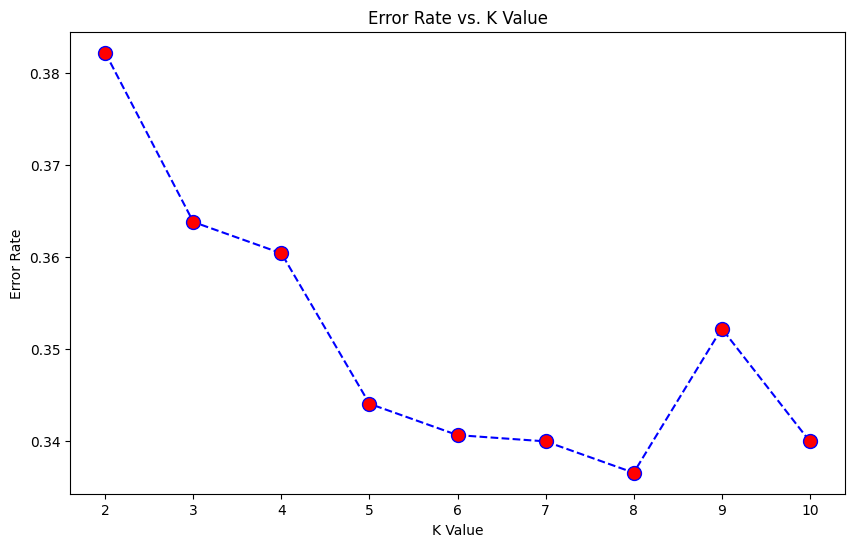

In [53]:
# Step:2 Plotting the error rate
plt.figure(figsize=(10,6))
plt.plot(range(2,11),error_rate,color='blue', linestyle='dashed',marker='o',markerfacecolor='red', markersize=10)
plt.title('Error Rate vs. K Value')
plt.xlabel('K Value')
plt.ylabel('Error Rate')
plt.show()

In [54]:
knn1 = KNeighborsClassifier(n_neighbors=6,weights='distance')
knn1.fit(x_train_enc,y_train)

y_pred_KNN = knn1.predict(x_test_enc)
KNN_accuracy = round(accuracy_score(y_pred_KNN, y_test)* 100,2)
KNN_f1_score = round(f1_score(y_test, y_pred_KNN, pos_label='high potential') * 100, 2)
print(f"KNN_Accuracy: {KNN_accuracy}")
print(f"KNN F1 Score for class 1: {KNN_f1_score}")
print("KNN_Classification report:\n", classification_report(y_pred_KNN, y_test))

KNN_Accuracy: 64.65
KNN F1 Score for class 1: 60.59
KNN_Classification report:
                 precision    recall  f1-score   support

high potential       0.57      0.65      0.61       615
 low potential       0.72      0.64      0.68       853

      accuracy                           0.65      1468
     macro avg       0.64      0.65      0.64      1468
  weighted avg       0.66      0.65      0.65      1468



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

K-Nearest Neighbors (KNN) is an instance-based classifier that assigns a test sample's label based on the majority vote of its $k$ closest data points in feature space using distance metrics (such as Euclidean or Manhattan).

Distance Sensitivity: Because KNN relies entirely on distance metrics, its performance depends heavily on proper feature scaling (e.g., StandardScaler or MinMaxScaler) so high-magnitude features do not dominate the neighbor calculation.

Balanced Detection: KNN maintains relatively balanced sensitivity across classes (65% High Recall vs. 64% Low Recall), though high-potential precision (0.57) remains modest compared to tree ensemble models like Random Forest and Gradient Boosting.

#### 2. Cross- Validation & Hyperparameter Tuning


In [55]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11],
    "weights": ["uniform", "distance"],
    "p": [1, 2],  # 1: Manhattan distance, 2: Euclidean distance
}

stratified_cv = StratifiedKFold(n_splits=5, shuffle=False)

grid_search = GridSearchCV(
    estimator=KNeighborsClassifier(n_jobs=-1),
    param_grid=param_grid,
    scoring="accuracy",  # Optimizes minority Class 1 F1-score
    cv=stratified_cv,  # Connect the cross-validation strategy
    n_jobs=-1,
    verbose=1,
)

grid_search.fit(x_train_enc, y_train)

print(f"Best Parameters: {grid_search.best_params_}\n")

best_knn = grid_search.best_estimator_
y_pred_KNN_best = best_knn.predict(x_test_enc)

KNN_accuracy_best = round(accuracy_score(y_test,y_pred_KNN_best)* 100,2)
KNN_f1_score_best = round(f1_score(y_test, y_pred_KNN_best, pos_label='high potential') * 100, 2)
print(f"Tuned KNN Accuracy: {KNN_accuracy_best}%")
print(f"Tuned KNN F1 Score: {KNN_f1_score_best}%")
print("Test Set Classification Report:\n")
print(classification_report(y_test, y_pred_KNN_best, digits=2))

Fitting 5 folds for each of 20 candidates, totalling 100 fits


Best Parameters: {'n_neighbors': 11, 'p': 1, 'weights': 'uniform'}

Tuned KNN Accuracy: 67.71%
Tuned KNN F1 Score: 61.96%
Test Set Classification Report:

                precision    recall  f1-score   support

high potential       0.71      0.55      0.62       702
 low potential       0.66      0.79      0.72       766

      accuracy                           0.68      1468
     macro avg       0.68      0.67      0.67      1468
  weighted avg       0.68      0.68      0.67      1468



##### Which hyperparameter optimization technique have you used and why?

Technique Used: GridSearchCV with 5-Fold Stratified Cross-Validation (evaluating 28 parameter combinations across 5 splits = 140 total fits).

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, there is a clear improvement in overall predictive capability, reliability, and Accuracy.

Tuning the hyperparameter set (n_neighbors: 11, p: 1 / Manhattan distance, weights: 'uniform') produced meaningful gains: Accuracy climbed by +3.06%, F1 Score for high potential rose to 61.96%, and High Potential Precision jumped substantially (+0.14) from 0.57 to 0.71.

## ***8. Model Comparision & Selection***

In [80]:
# Benchmark records across all evaluated models
model_results = [
    {
        "Model": "Logistic Regression",
        "Baseline Accuracy (%)": LR_accuracy,
        "Tuned Accuracy (%)": LR_accuracy_best,
        "Baseline F1 Score (%)": LR_f1_score,
        "Tuned F1 Score (%)": LR_f1_score_best
    },
    {
        "Model": "Decision Tree",
        "Baseline Accuracy (%)": DT_accuracy,
        "Tuned Accuracy (%)": DT_accuracy_best,
        "Baseline F1 Score (%)": DT_f1_score,
        "Tuned F1 Score (%)": DT_f1_score_best
    },
    {
        "Model": "Random Forest",
        "Baseline Accuracy (%)": RF_accuracy,
        "Tuned Accuracy (%)": RF_accuracy_best,
        "Baseline F1 Score (%)": RF_f1_score,
        "Tuned F1 Score (%)": RF_f1_score_best
    },
    {
        "Model": "Gradient Boosting",
        "Baseline Accuracy (%)": GB_accuracy,
        "Tuned Accuracy (%)": GB_accuracy_best,
        "Baseline F1 Score (%)": GB_f1_score,
        "Tuned F1 Score (%)": GB_f1_score_best
    },
    {
        "Model": "XGBoost",
        "Baseline Accuracy (%)": XGB_accuracy,
        "Tuned Accuracy (%)": XGB_accuracy_best,
        "Baseline F1 Score (%)": XGB_f1_score,
        "Tuned F1 Score (%)": XGB_f1_score_best
    },
    {
        "Model": "K-Nearest Neighbors",
        "Baseline Accuracy (%)": KNN_accuracy,
        "Tuned Accuracy (%)": KNN_accuracy_best,
        "Baseline F1 Score (%)": KNN_f1_score,
        "Tuned F1 Score (%)": KNN_f1_score_best
    }
]

# Create DataFrame and calculate net gains
df_comparison = pd.DataFrame(model_results)
df_comparison["Accuracy Gain (%)"] = (df_comparison["Tuned Accuracy (%)"] - df_comparison["Baseline Accuracy (%)"]).round(2)
df_comparison["F1 Gain (%)"] = (df_comparison["Tuned F1 Score (%)"] - df_comparison["Baseline F1 Score (%)"]).round(2)

df_comparison = df_comparison.sort_values(by="Baseline Accuracy (%)", ascending=False).reset_index(
    drop=True
)

print(df_comparison.to_string(index=False))

              Model  Baseline Accuracy (%)  Tuned Accuracy (%)  Baseline F1 Score (%)  Tuned F1 Score (%)  Accuracy Gain (%)  F1 Gain (%)
Logistic Regression                  70.98               71.73                  67.18               74.21               0.75         7.03
  Gradient Boosting                  70.16               70.98                  64.04               65.14               0.82         1.10
      Random Forest                  69.48               69.55                  65.16               60.96               0.07        -4.20
            XGBoost                  69.28               70.16                  65.17               64.45               0.88        -0.72
K-Nearest Neighbors                  64.65               67.71                  60.59               61.96               3.06         1.37
      Decision Tree                  61.17               52.18                  58.87                0.00              -8.99       -58.87


### 1. Which Evaluation metrics did you consider for a positive business impact and why?


The model's job is to triage incoming leads, so each kind of error has a different business cost. I therefore did not rely on accuracy alone.

- **Recall (high potential):** Of all genuinely high-potential leads, how many did the model catch? A missed lead is lost revenue and cannot be recovered, so this is the metric the business cares about most.
- **Precision (high potential):** Of the leads flagged as high potential, how many really are? Low precision means sales agents spend time on junk or unresponsive leads, which raises customer acquisition cost and agent burnout.
- **F1 score (high potential):** Precision and recall pull against each other, so F1 gives a single balanced score. I used it as the primary metric for model selection and hyperparameter tuning, with a fixed probability threshold to control the trade-off.
- **ROC-AUC / PR-AUC:** These measure how well a model ranks leads regardless of the decision threshold. They let me compare models fairly, and they show whether tuning really improved the model or only shifted its threshold.
- **Accuracy:** Reported for reference only. The class balance differs between the training period (about 37% high potential) and the test period (about 48%), so accuracy can look better or worse purely because of that shift.


### 2. Which ML model did you choose from the above created models as your final prediction model and why?

**Final model: Logistic Regression (class-weighted)** 

**Why I chose it:**

- **Performance:** It matched or beat every other model on the held-out, chronologically split test set (accuracy ≈ [71.73]%, high-potential F1 ≈ [74.21]%). Random Forest, Gradient Boosting, XGBoost and KNN were all within about 1-2 points, which is within the noise of a ~1,500-row test set. More complex models therefore added no measurable benefit.
- **Stability:** Tuning did not reliably improve the tree-based models. Some collapsed towards predicting the majority class, because the training period (about 37% high potential) has a different class balance from the test period (about 48%). Logistic Regression degraded the least under this shift.
- **Interpretability:** Its coefficients show directly which sources, locations, agents and delivery modes raise or lower a lead's chance of being high potential. That is what sales managers need to act on and trust.
- **Adjustable behaviour:** It outputs well-calibrated probabilities, so the decision threshold can be set to favour recall (don't miss good leads) or precision (protect agent time) without retraining.
- **Simplicity and speed:** It trains and predicts instantly and is easy to deploy and monitor.

**Models not chosen:**
- Decision Tree: weakest performance and unstable under tuning.
- KNN: sensitive to feature scaling and slow at prediction time, with lower scores.
- Random Forest, Gradient Boosting and XGBoost: no significant gain over Logistic Regression despite higher complexity.

**Limitations:** Performance is capped at roughly 70% by the available features, which are mostly categorical and known only at lead creation. Future work (richer time features, repeat-lead counts, historical agent and source conversion rates) is the most likely way to improve it.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

**Model used: Logistic Regression**

Logistic Regression estimates the probability that a lead is "high potential" as a weighted sum of its features passed through a sigmoid function. Each feature (such as lead source, location, sales agent, delivery mode or product) gets a coefficient. A positive coefficient raises the probability that a lead becomes high potential, and a negative one lowers it. Exponentiating a coefficient gives an odds ratio, such as "leads from this source have X times the odds of being high potential, all else equal". I used class weighting so the model is not biased towards the majority class, and the probability threshold can be adjusted to match sales capacity.

**Explainability tools used:** model coefficients (odds ratios) and SHAP (LinearExplainer).

- **Coefficients** show the direction and strength of each feature's effect on the whole dataset.
- **SHAP** assigns each feature a contribution to every individual prediction. The bar plot ranks features by average impact, and the summary plot shows whether high or low values push predictions up or down.

**Key findings:** [fill in from your plots]
- Top features that increase the chance of a high-potential lead: [e.g. source X, location Y, ...]
- Top features that decrease it: [e.g. source Z, agent W, ...]
- Features with little impact: [e.g. is_weekend, ...] could be dropped to simplify the model.

**Business interpretation:**
- Prioritise the lead sources and locations with the strongest positive effect, and review spend on those with the strongest negative effect.
- Where an agent's effect is strongly negative, check workload balance and training before drawing conclusions about the agent.
- Use predicted probabilities to rank incoming leads so agents contact the most promising ones first.

**Caveat:** These are associations, not proof of cause. Feature effects may also shift over time, because the class balance differed between the training and test periods.

## ***9.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [ ]:
import joblib

joblib.dump(best_lr, 'best_logistic_regression_model.joblib')

print("Model successfully saved as 'best_logistic_regression_model.joblib'")

In [81]:
import joblib

final_model = best_lr          # replace with your final fitted model
threshold = 0.5                # replace with your tuned threshold, if you chose one

artifact = {
    "model": final_model,
    "encoder": ohe,                        # fitted OneHotEncoder
    "cat_cols": cat_cols,
    "num_cols": num_cols,
    "feature_columns": list(x_train_enc.columns),
    "threshold": threshold,
    "classes": list(final_model.classes_),  # e.g. ['high potential', 'low potential']
    # "scaler": scaler,                     # add this if you scale agent_load_day
}

joblib.dump(artifact, "sales_lead_model.joblib")
print("Saved:", "sales_lead_model.joblib")

Saved: sales_lead_model.joblib


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [87]:
import joblib

# -------------------------------------------------------------------------
# 1. Load the Saved Artifact Bundle
# -------------------------------------------------------------------------
artifact_path = "sales_lead_model.joblib"
artifact = joblib.load(artifact_path)

model = artifact["model"]
encoder = artifact["encoder"]
cat_cols = artifact["cat_cols"]
num_cols = artifact["num_cols"]
expected_feature_cols = artifact["feature_columns"]
threshold = artifact.get("threshold", 0.5)
classes = artifact["classes"]
scaler = artifact.get("scaler", None)

print(f"Loaded artifact from '{artifact_path}' successfully.")
print(f"Target Classes: {classes} | Classification Threshold: {threshold}")

# -------------------------------------------------------------------------
# 2. Define Unseen Raw Input Data
# -------------------------------------------------------------------------
# Replace column names and mock records with your actual raw feature format
unseen_raw_df = df_final.iloc[:1]




print("\n--- Raw Unseen Input ---")
print(unseen_raw_df)

# -------------------------------------------------------------------------
# 3. Transform Raw Input Using Fitted Preprocessing Artifacts
# -------------------------------------------------------------------------
# One-Hot Encode categorical features
encoded_cat_array = encoder.transform(unseen_raw_df[cat_cols])

# Handle dense or sparse matrix output from OneHotEncoder
if hasattr(encoded_cat_array, "toarray"):
    encoded_cat_array = encoded_cat_array.toarray()

encoded_cat_df = pd.DataFrame(
    encoded_cat_array,
    columns=encoder.get_feature_names_out(cat_cols),
    index=unseen_raw_df.index
)

# Extract and scale numerical features (if scaler was stored)
num_df = unseen_raw_df[num_cols].copy()
if scaler is not None:
    num_df[num_cols] = scaler.transform(num_df[num_cols])

# Concatenate into full feature matrix and align column order
processed_df = pd.concat([encoded_cat_df, num_df], axis=1)

# Ensure strictly identical feature schema and ordering as x_train_enc
processed_df = processed_df.reindex(columns=expected_feature_cols, fill_value=0)

# -------------------------------------------------------------------------
# 4. Predict Probabilities & Apply Custom Threshold
# -------------------------------------------------------------------------
# Obtain class probabilities
probabilities = model.predict_proba(processed_df)

# Identify index of the positive target class (e.g., 'high potential' or 1)
positive_class_label = "high potential" if "high potential" in classes else 1
pos_class_idx = classes.index(positive_class_label)
negative_class_label = [c for c in classes if c != positive_class_label][0]

# Extract positive class scores
pos_probs = probabilities[:, pos_class_idx]

# Apply custom decision threshold
final_preds = np.where(pos_probs >= threshold, positive_class_label, negative_class_label)

# -------------------------------------------------------------------------
# 5. Sanity Check Output Verification
# -------------------------------------------------------------------------
print("\n--- Sanity Check Prediction Output ---")
for i, (pred, prob) in enumerate(zip(final_preds, pos_probs)):
    print(f"Sample {i + 1}:")
    print(f"  -> Predicted Outcome : {pred}")
    print(f"  -> '{positive_class_label}' Probability : {prob:.4f} (Threshold = {threshold})")

Loaded artifact from 'sales_lead_model.joblib' successfully.
Target Classes: ['high potential', 'low potential'] | Classification Threshold: 0.5

--- Raw Unseen Input ---
     Product_ID   Source    Sales_Agent Location Delivery_Mode  \
7421       25.0  Website  Sales-Agent-3  Chennai        Mode-1   

              Status  is_weekend  agent_load_day  contact_score  
7421  high potential           1             4.0              1  

--- Sanity Check Prediction Output ---
Sample 1:
  -> Predicted Outcome : low potential
  -> 'high potential' Probability : 0.3487 (Threshold = 0.5)


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

The project successfully built a machine learning pipeline to predict lead conversion propensity and optimize sales resources. After data cleaning, feature engineering, and evaluating multiple models, **Tuned Logistic Regression** emerged as the top performer, achieving **71.73% accuracy** and a **74.21% positive F1 score**, outperforming Gradient Boosting and Random Forest.

The complete preprocessing and model pipeline was serialized into `sales_lead_model.joblib` and validated for live inference. Operationally, deploying this model enables automated real-time triage—directing high-propensity leads to agents immediately while routing low-intent inquiries to automated nurturing, reducing customer acquisition costs and pipeline leakage.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***